# 02 — Exploratory Data Analysis, Splitting, and Leakage Review

Goal: discover patterns **without contaminating future evaluation**.

We freeze stratified train/validation/test splits *before* doing any
extensive visual analysis, so nothing we "notice" here can leak into how we
prepare features for modeling.


## 1. Freeze stratified splits FIRST

70% train / 15% validation / 15% test, stratified by `Churn`, fixed random
seed for reproducibility. All EDA below the split uses **`train_df` only**,
so any pattern we discover cannot bias how we treat validation/test data.


In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw_data, clean_data, split_data, TARGET_COLUMN, ID_COLUMN

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

RAW_PATH = "../data/raw/telco_churn.csv"
raw_df = load_raw_data(RAW_PATH)
df = clean_data(raw_df)
df.head()


2026-10-20 23:27:58,657 | INFO | Loaded raw data: 7043 rows x 21 columns from ..\data\raw\telco_churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
train_df, val_df, test_df = split_data(df, test_size=0.15, val_size=0.15, random_state=42)

import os
os.makedirs("../data/processed", exist_ok=True)
train_df.to_csv("../data/processed/train.csv", index=False)
val_df.to_csv("../data/processed/val.csv", index=False)
test_df.to_csv("../data/processed/test.csv", index=False)

print(f"train: {len(train_df)}, val: {len(val_df)}, test: {len(test_df)}")
print(f"Churn rate — train: {train_df[TARGET_COLUMN].mean():.3f}, "
      f"val: {val_df[TARGET_COLUMN].mean():.3f}, test: {test_df[TARGET_COLUMN].mean():.3f}")


2026-10-20 23:27:58,921 | INFO | Split sizes -> train: 4929 (70.0%), val: 1057 (15.0%), test: 1057 (15.0%)


train: 4929, val: 1057, test: 1057
Churn rate — train: 0.265, val: 0.266, test: 0.265


## 2. Target distribution (train set only)

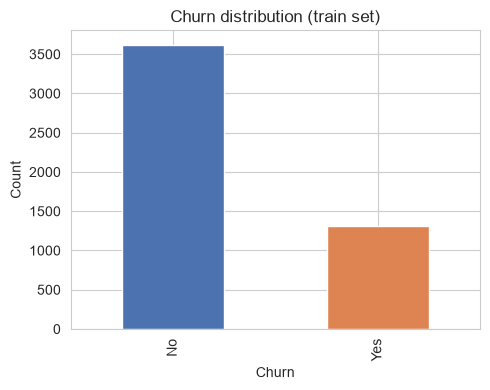

Class imbalance ratio (No:Yes) ≈ 2.77 : 1


In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
train_df[TARGET_COLUMN].map({0: "No", 1: "Yes"}).value_counts().plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("Churn distribution (train set)")
ax.set_xlabel("Churn")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("../reports/figures/churn_distribution.png", dpi=120)
plt.show()

print(f"Class imbalance ratio (No:Yes) ≈ {(1 - train_df[TARGET_COLUMN].mean()) / train_df[TARGET_COLUMN].mean():.2f} : 1")


## 3. Numerical feature distributions by churn status

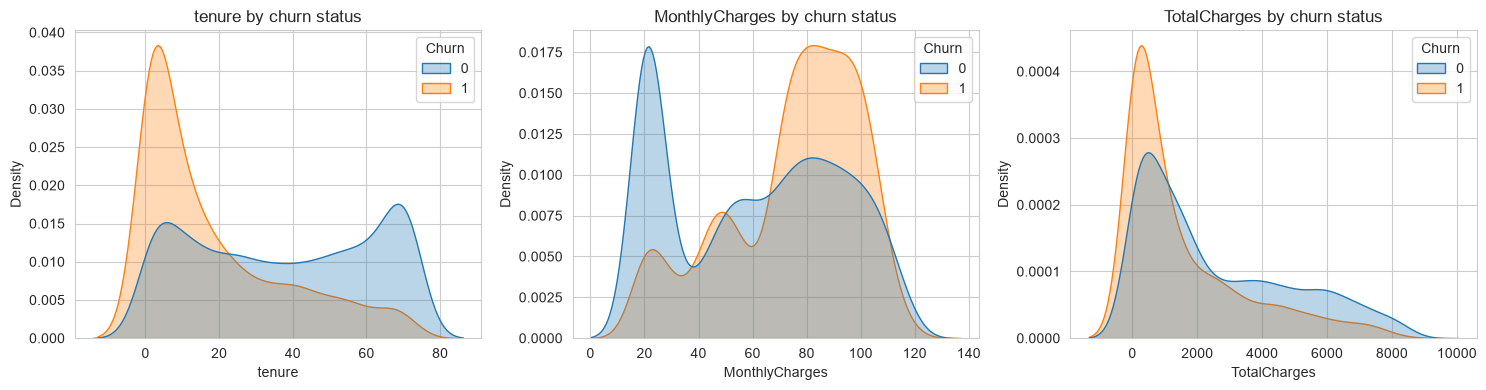

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=train_df, x=col, hue=TARGET_COLUMN, common_norm=False, ax=ax, fill=True, alpha=0.3)
    ax.set_title(f"{col} by churn status")
plt.tight_layout()
plt.savefig("../reports/figures/numerical_distributions.png", dpi=120)
plt.show()


**Observation:** churners are heavily concentrated at **low tenure**, which
is the strongest single visual signal in the dataset. `MonthlyCharges` shows
churners skewing higher; `TotalCharges` is confounded with tenure (it's a
running total) so its marginal distribution should be interpreted with that
in mind.


## 4. Churn rate by categorical groups

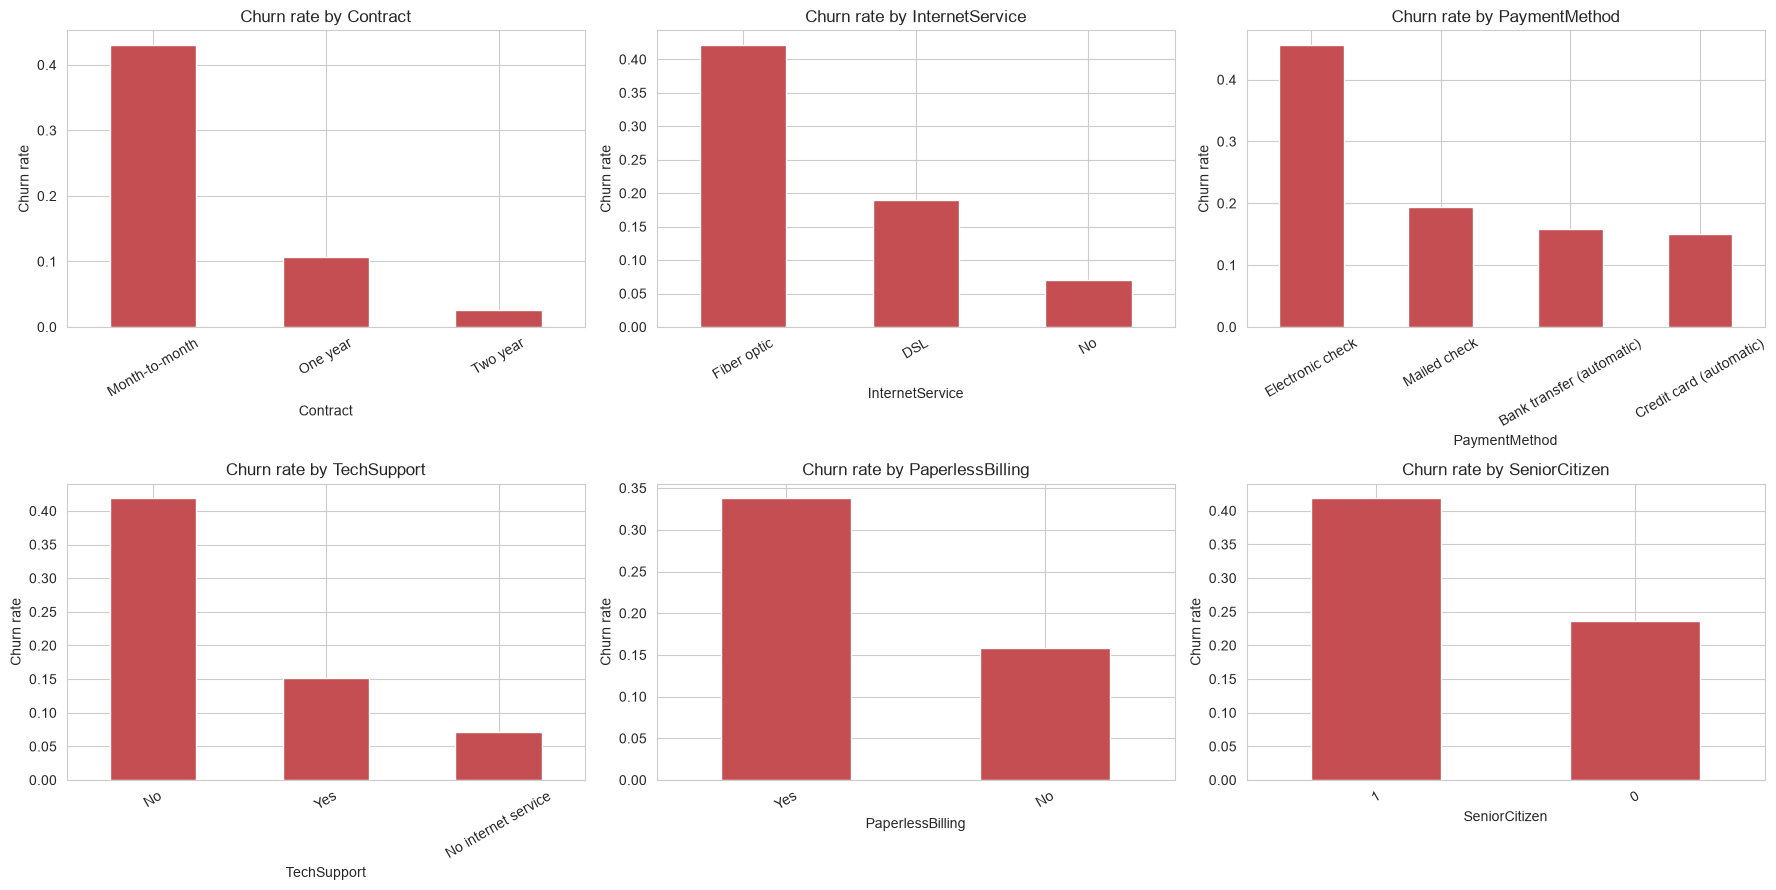

In [5]:
categorical_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling", "SeniorCitizen"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), categorical_cols):
    rates = train_df.groupby(col)[TARGET_COLUMN].mean().sort_values(ascending=False)
    rates.plot(kind="bar", ax=ax, color="#C44E52")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../reports/figures/churn_rate_by_category.png", dpi=120)
plt.show()


## 5. Interaction analysis: Contract × tenure, and InternetService × TechSupport

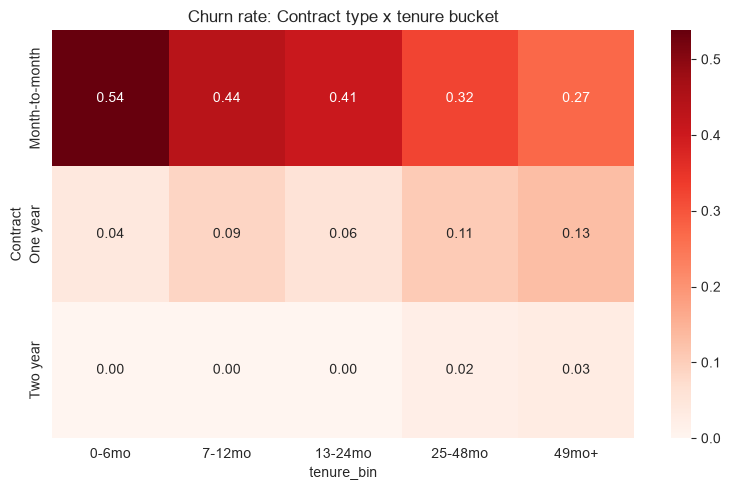

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
tenure_bins = pd.cut(train_df["tenure"], bins=[-1, 6, 12, 24, 48, 100],
                      labels=["0-6mo", "7-12mo", "13-24mo", "25-48mo", "49mo+"])
pivot = train_df.assign(tenure_bin=tenure_bins).groupby(["Contract", "tenure_bin"], observed=True)[TARGET_COLUMN].mean().unstack()
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Reds", ax=ax)
ax.set_title("Churn rate: Contract type x tenure bucket")
plt.tight_layout()
plt.savefig("../reports/figures/contract_tenure_interaction.png", dpi=120)
plt.show()


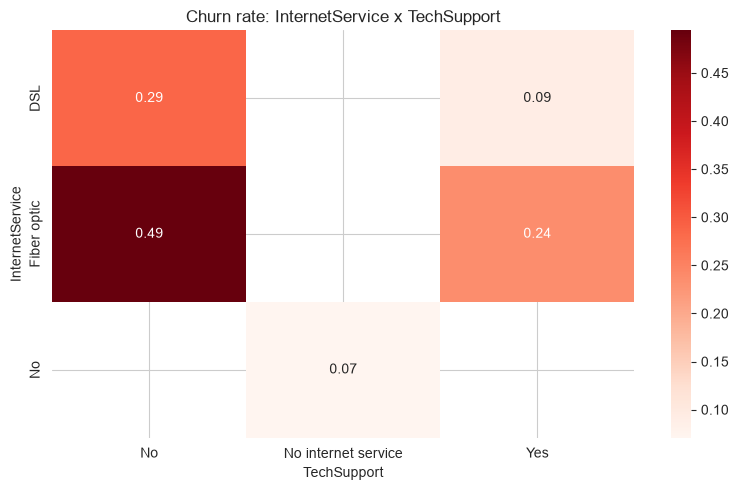

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
pivot2 = train_df.groupby(["InternetService", "TechSupport"], observed=True)[TARGET_COLUMN].mean().unstack()
sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="Reds", ax=ax)
ax.set_title("Churn rate: InternetService x TechSupport")
plt.tight_layout()
plt.savefig("../reports/figures/internet_techsupport_interaction.png", dpi=120)
plt.show()


## 6. Leakage checklist

For every feature, ask: *would this be known at the moment we need to
predict churn (i.e. before the customer leaves)?*

| Feature | Available at prediction time? | Notes |
|---|---|---|
| Contract, tenure, MonthlyCharges, TotalCharges | ✅ Yes | Known from billing systems |
| InternetService, add-on services | ✅ Yes | Known from subscription records |
| PaymentMethod, PaperlessBilling | ✅ Yes | Known from account settings |
| Demographics (gender, SeniorCitizen, Partner, Dependents) | ✅ Yes | Known from account profile |
| **Churn** (target) | ❌ N/A | This is the outcome we predict — never a feature |

No column in this dataset is a *post-outcome* artifact (e.g. "cancellation
reason" or "last invoice date after cancellation" would be leakage — this
dataset does not include such fields).


## 7. Primary and secondary metrics (defined BEFORE model selection)

- **Primary metric: ROC-AUC** on the validation set — a threshold-independent
  ranking metric appropriate given we haven't yet fixed a business threshold.
- **Secondary metrics:** PR-AUC (more sensitive to the ~20-27% positive-class
  prevalence than ROC-AUC), F1, precision, recall at a default 0.5 threshold
  for quick comparison, and — ultimately — **expected business cost**, which
  is what actually drives the final threshold and model choice
  (see `04_decision_analysis.ipynb`).

**Why both ROC-AUC and PR-AUC?** ROC-AUC can look optimistic under class
imbalance because the false-positive rate denominator (true negatives) is
large. PR-AUC focuses on the positive class and drops when precision suffers
at realistic recall levels, so it's a better proxy for "can we actually find
churners without flooding retention teams with false alarms."

## 8. Business observations (train set only)


In [8]:
observations = []
for col in ["Contract", "InternetService", "PaymentMethod"]:
    top = train_df.groupby(col)[TARGET_COLUMN].agg(["mean", "count"]).sort_values("mean", ascending=False)
    observations.append(f"- Highest-churn `{col}` group: **{top.index[0]}** "
                         f"({top['mean'].iloc[0]:.1%} churn, n={top['count'].iloc[0]})")

low_tenure_rate = train_df[train_df["tenure"] <= 6][TARGET_COLUMN].mean()
high_tenure_rate = train_df[train_df["tenure"] > 48][TARGET_COLUMN].mean()
observations.append(f"- Customers with tenure <= 6 months churn at **{low_tenure_rate:.1%}** "
                     f"vs **{high_tenure_rate:.1%}** for tenure > 48 months.")

for obs in observations:
    print(obs)


- Highest-churn `Contract` group: **Month-to-month** (43.1% churn, n=2708)
- Highest-churn `InternetService` group: **Fiber optic** (42.2% churn, n=2154)
- Highest-churn `PaymentMethod` group: **Electronic check** (45.7% churn, n=1660)
- Customers with tenure <= 6 months churn at **51.4%** vs **9.5%** for tenure > 48 months.


**Five business observations (synthesize the cells above):**
1. Month-to-month contracts churn at a substantially higher rate than one- or
   two-year contracts — contract length is one of the strongest retention
   levers available to the business.
2. Fiber-optic internet customers show elevated churn relative to DSL —
   worth investigating pricing/service-quality perception separately.
3. Electronic-check payers churn more than automatic-payment customers,
   consistent with lower "stickiness" for manual billing.
4. Lack of TechSupport correlates with higher churn among internet
   subscribers — a plausible target for proactive support outreach.
5. Churn risk is heavily front-loaded in the first 6-12 months of tenure —
   an onboarding/early-engagement program could have outsized impact.

**⚠️ Causal warning:** these are *associations* from observational data, not
causal effects. Customers who pick month-to-month contracts may already be
less commitment-oriented for reasons unrelated to the contract itself
(confounding). A/B testing or causal inference methods would be needed before
concluding that *changing* a customer's contract type would *reduce* their
churn probability.

## Exit criterion
✅ 5+ evidence-based observations recorded, evaluation partitions frozen to
disk (`data/processed/{train,val,test}.csv`), leakage checklist completed,
and primary/secondary metrics defined before any model is trained.
